In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from evalu import cv_scores, plot_curve

In [2]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


In [3]:
clf = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(C=1.0, max_iter=2000))])
r_clf = cv_scores(X_train, clf, y_clf, "classification")
print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'accuracy': np.float64(0.5084), 'accuracy_std': np.float64(0.0301), 'f1': np.float64(0.3405), 'f1_std': np.float64(0.2138), 'roc_auc': np.float64(0.5069), 'roc_auc_std': np.float64(0.0486)}


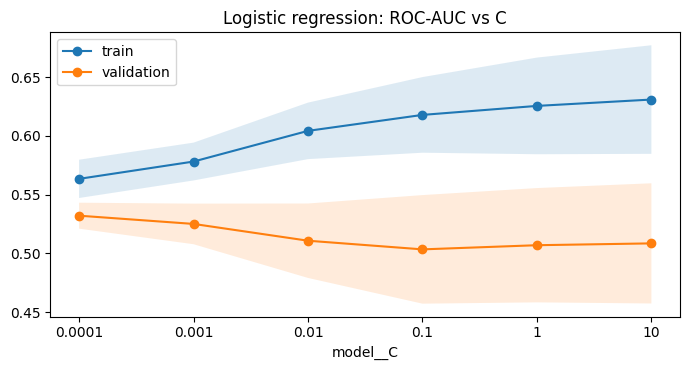

,value,train,validation
0,0.0001,0.563,0.532
1,0.001,0.578,0.525
2,0.01,0.604,0.511
3,0.1,0.618,0.503
4,1,0.625,0.507
5,10,0.631,0.508


In [4]:
cs = plot_curve(clf, X_train, y_clf, "model__C", [0.0001, 0.001, 0.01, 0.1, 1, 10], "roc_auc", "Logistic regression: ROC-AUC vs C", "logreg_C.png")
cs.round(3)

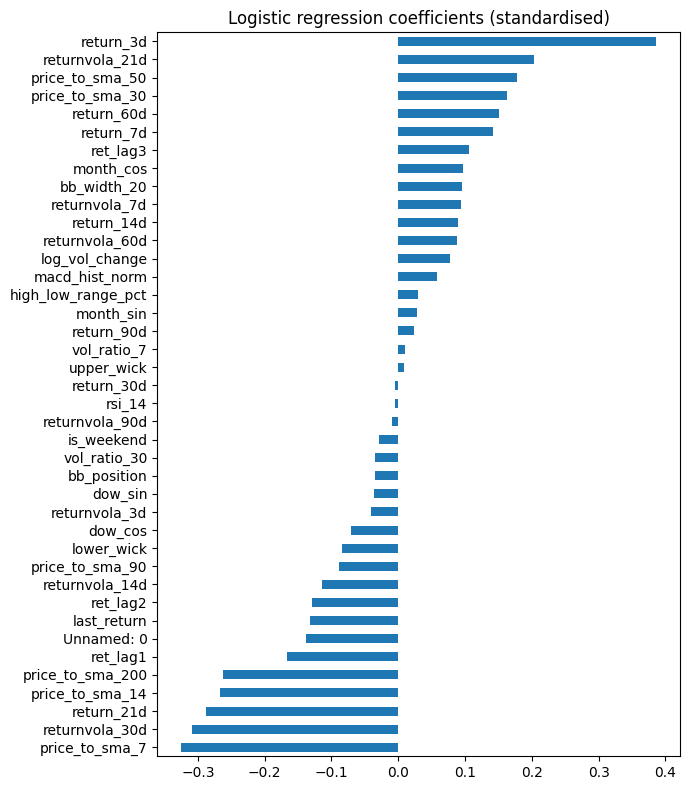

{'return_60d': 1.164, 'price_to_sma_30': 1.177, 'price_to_sma_50': 1.195, 'returnvola_21d': 1.225, 'return_3d': 1.472}
{'price_to_sma_7': 0.722, 'returnvola_30d': 0.734, 'return_21d': 0.75, 'price_to_sma_14': 0.766, 'price_to_sma_200': 0.77}


In [5]:
clf.fit(X_train, y_clf)
coef = pd.Series(clf.named_steps["model"].coef_[0], index=X_train.columns).sort_values()
odds = np.exp(coef).round(3)
fig, ax = plt.subplots(figsize=(7, 8)); coef.plot.barh(ax=ax); ax.set_title("Logistic regression coefficients (standardised)")
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/logreg_coefficients.png", dpi=130); plt.show()
print(odds.tail(5).to_dict()); print(odds.head(5).to_dict())

Coefficients are small; no single feature changes the odds by more than a few percent per std.

In [6]:
bal = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced"))])
print("default :", {k: round(v, 4) for k, v in r_clf.items() if k in ("accuracy", "roc_auc")})
rb = cv_scores(X_train, bal, y_clf, "classification"); print("balanced:", {k: round(v, 4) for k, v in rb.items() if k in ("accuracy", "roc_auc")})

default : {'accuracy': np.float64(0.5084), 'roc_auc': np.float64(0.5069)}
balanced: {'accuracy': np.float64(0.5145), 'roc_auc': np.float64(0.507)}


In [7]:
rows = [{"model": "Logistic Regression", **r_clf}]
res = pd.DataFrame(rows)
res.to_csv("../../03.results/logs/model_results_logistic_regression.csv", index=False)
res.round(4)

,model,task,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,Logistic Regression,classification,0.5084,0.0301,0.3405,0.2138,0.5069,0.0486
